# Taller 3
## Análisis de Redes y Sistemas de Recomendación

Fuente: **MovieLens 100K** (100 000 calificaciones de 943 usuarios sobre 1 682 películas), cargado desde archivos locales. Obtenido de:  https://files.grouplens.org/datasets/movielens/ml-100k.zip

**Preguntas planteadas:**
1. **Análisis de redes con `networkx`**:
   - Identifica los 5 usuarios que califican más películas.
   - Determina cuáles son las películas más centrales en la red.
   - Visualiza la red con un enfoque en las comunidades.

2. **Sistemas de recomendación con `surprise`**: 
   - Compara el rendimiento de los modelos SVD y KNN en términos de RMSE.
   - Optimiza los hiperparámetros para obtener el RMSE más bajo posible.
   - Genera recomendaciones de las 5 mejores películas para un usuario específico.

## 0. Configuración

Todas las rutas y parámetros generales están en la siguiente celda. Ajusta `ruta_carpeta` a la carpeta donde descomprimiste el zip (la que contiene `u.data` y `u.item`).

In [1]:
import os
import time
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from networkx.algorithms import bipartite, community

from surprise import Dataset, Reader, SVD, KNNBasic, KNNWithMeans, accuracy
from surprise.model_selection import train_test_split, GridSearchCV

In [2]:
# --- Parámetros generales ---
# Carga de u.data y u.item
ruta_carpeta = r"D:\MCD_UITEY\2_fundamentos_de_ciencia_de_datos\taller_03\ml-100k"
semilla = 42

# --- Estilo de gráficos ---
colores = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
color_otros = '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'axes.titlecolor': '#0b0b0b',
    'xtick.color': '#898781', 'ytick.color': '#898781',
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
})

## 1. Análisis de redes con `networkx`

### 1.1. Preparación del conjunto de datos

Para el análisis de redes se leen: 

- `u.data` con las columnas usuario, película, calificación y timestamp separadas por tabulación, y
- `u.item` tiene los títulos, separado por `|` y codificado en latin-1.

In [3]:
ratings = pd.read_csv(os.path.join(ruta_carpeta, 'u.data'), sep='\t', header=None,
                      names=['user', 'item', 'rating', 'timestamp'])
peliculas = pd.read_csv(os.path.join(ruta_carpeta, 'u.item'), sep='|', encoding='latin-1', header=None,
                        usecols=[0, 1], names=['item', 'titulo'])

print(f"Calificaciones: {len(ratings):,} | Usuarios: {ratings['user'].nunique()} | Películas: {ratings['item'].nunique()}")
ratings.head()

Calificaciones: 100,000 | Usuarios: 943 | Películas: 1682


,user,item,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [4]:
print(f"Cantidad de títulos: {len(peliculas)}")
peliculas.head()

Cantidad de títulos: 1682


,item,titulo
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [5]:
# Verificación de duplicados por nombre y usuario
print(f"Registros duplicados por usuario y película: {ratings.duplicated(['user', 'item']).sum()}")

Registros duplicados por usuario y película: 0


#### 1.1.1. Grafo bipartito

Los IDs de usuarios y películas son enteros que se solapan (existe el usuario 1 y la película 1), así que se antepone un prefijo para que sean nodos distintos: `u196` es un usuario y `m302` una película. Cada arista une a un usuario con una película que calificó, y guarda la calificación como peso.

In [6]:
nodos_usuarios = ['u' + str(u) for u in ratings['user'].unique()]
nodos_peliculas = ['m' + str(m) for m in ratings['item'].unique()]
titulo = dict(zip('m' + peliculas['item'].astype(str), peliculas['titulo']))

G = nx.Graph()
G.add_nodes_from(nodos_usuarios, bipartite=0, tipo='usuario')
G.add_nodes_from(nodos_peliculas, bipartite=1, tipo='película')
G.add_weighted_edges_from(zip('u' + ratings['user'].astype(str),
                              'm' + ratings['item'].astype(str),
                              ratings['rating']))

print(G)
print('¿Bipartito?:', nx.is_bipartite(G))
print('¿Conexo?:  ', nx.is_connected(G))
print(f'Densidad:   {bipartite.density(G, nodos_usuarios):.4f}  (fracción de pares usuario–película con calificación)')

Graph with 2625 nodes and 100000 edges
¿Bipartito?: True
¿Conexo?:   True
Densidad:   0.0630  (fracción de pares usuario–película con calificación)


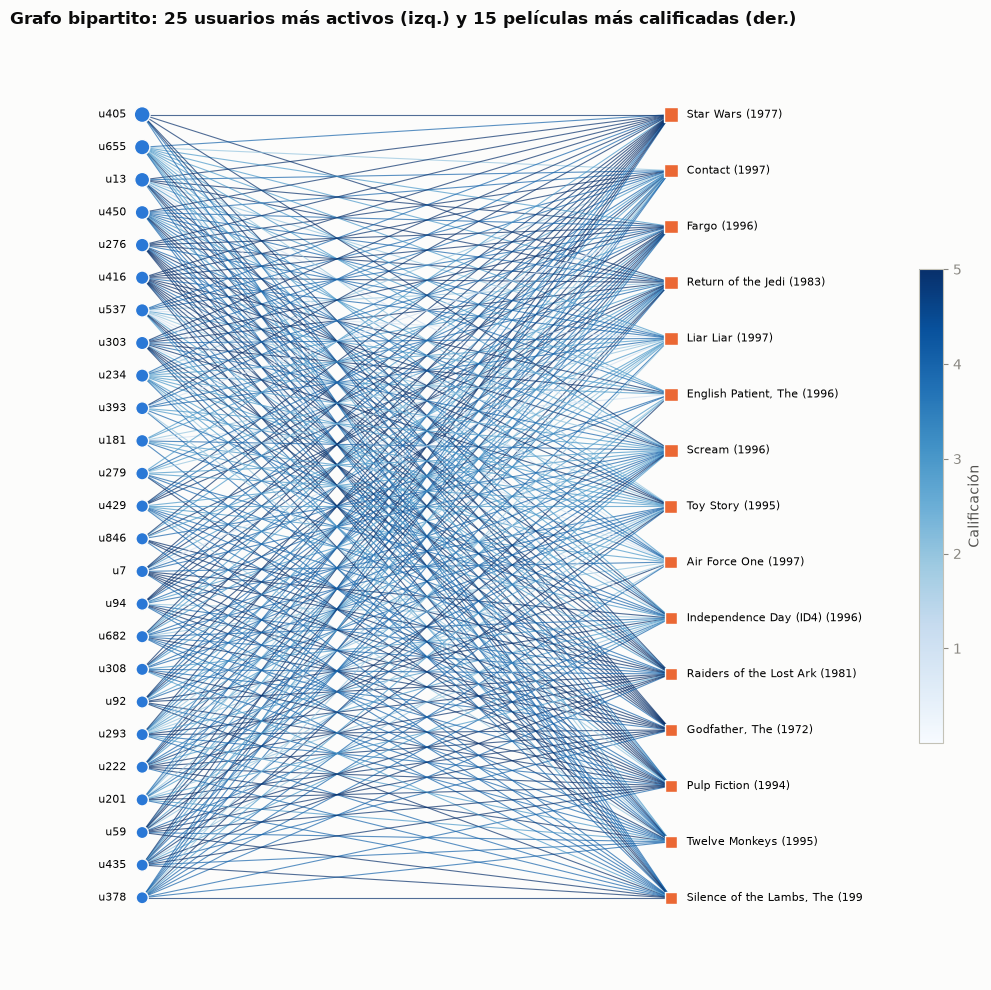

In [7]:
n_usuarios_vis = 25
n_peliculas_vis = 15

usuarios_vis = ['u' + str(u) for u in ratings['user'].value_counts().index[:n_usuarios_vis]]
peliculas_vis = ['m' + str(m) for m in ratings['item'].value_counts().index[:n_peliculas_vis]]
B = G.subgraph(usuarios_vis + peliculas_vis)

pos = {n: (0, -i / (n_usuarios_vis - 1)) for i, n in enumerate(usuarios_vis)}
pos.update({n: (1, -i / (n_peliculas_vis - 1)) for i, n in enumerate(peliculas_vis)})
pesos = [w for _, _, w in B.edges(data='weight')]

fig, ax = plt.subplots(figsize=(11, 10))
nx.draw_networkx_edges(B, pos, ax=ax, edge_color=pesos, edge_cmap=plt.cm.Blues,
                       edge_vmin=0, edge_vmax=5, width=0.8, alpha=0.7)
nx.draw_networkx_nodes(B, pos, nodelist=usuarios_vis, node_shape='o', node_color=colores[0],
                       node_size=[20 + 0.15 * G.degree(n) for n in usuarios_vis], edgecolors='#fcfcfb', ax=ax)
nx.draw_networkx_nodes(B, pos, nodelist=peliculas_vis, node_shape='s', node_color=colores[1],
                       node_size=[20 + 0.15 * G.degree(n) for n in peliculas_vis], edgecolors='#fcfcfb', ax=ax)
nx.draw_networkx_labels(B, {n: (x - 0.03, y) for n, (x, y) in pos.items() if n in usuarios_vis},
                        labels={n: n for n in usuarios_vis}, font_size=8, horizontalalignment='right', ax=ax)
nx.draw_networkx_labels(B, {n: (x + 0.03, y) for n, (x, y) in pos.items() if n in peliculas_vis},
                        labels={n: titulo[n][:30] for n in peliculas_vis}, font_size=8, horizontalalignment='left', ax=ax)
plt.colorbar(plt.cm.ScalarMappable(cmap=plt.cm.Blues, norm=plt.Normalize(0, 5)), ax=ax,
             shrink=0.5, pad=0.01, ticks=[1, 2, 3, 4, 5], label='Calificación')
ax.set_title(f'Grafo bipartito: {n_usuarios_vis} usuarios más activos (izq.) y {n_peliculas_vis} películas más calificadas (der.)', loc='left')
ax.set_xlim(-0.25, 1.45)
ax.axis('off')
plt.tight_layout()
plt.show()

### 1.2. Análisis del grafo

#### 1.2.1. Centralidad de grado

En un grafo bipartito, el grado de un usuario es cuántas películas calificó, y el de una película es cuántos usuarios la calificaron. `bipartite.degree_centrality` normaliza cada grado por el tamaño del **otro** conjunto: un usuario con centralidad 0,4 calificó el 40 % de las películas.

In [8]:
n_top_usuarios = 5
n_top_peliculas = 10

centralidad_grado = bipartite.degree_centrality(G, nodos_usuarios)
tabla_grado = pd.DataFrame({
    'nodo': list(G.nodes),
    'tipo': [G.nodes[n]['tipo'] for n in G.nodes],
    'grado': [G.degree(n) for n in G.nodes],
    'centralidad_grado': [centralidad_grado[n] for n in G.nodes],
})

top_usuarios = tabla_grado[tabla_grado['tipo'] == 'usuario'].nlargest(n_top_usuarios, 'grado')
top_peliculas_grado = tabla_grado[tabla_grado['tipo'] == 'película'].nlargest(n_top_peliculas, 'grado').copy()
top_peliculas_grado['titulo'] = top_peliculas_grado['nodo'].map(titulo)

print(f'Top {n_top_usuarios} usuarios que más películas califican:')
display(top_usuarios.reset_index(drop=True))
print(f'Top {n_top_peliculas} películas más calificadas:')
display(top_peliculas_grado[['nodo', 'titulo', 'grado', 'centralidad_grado']].reset_index(drop=True))

Top 5 usuarios que más películas califican:


,nodo,tipo,grado,centralidad_grado
0,u405,usuario,737,0.438169
1,u655,usuario,685,0.407253
2,u13,usuario,636,0.378121
3,u450,usuario,540,0.321046
4,u276,usuario,518,0.307967


Top 10 películas más calificadas:


,nodo,titulo,grado,centralidad_grado
0,m50,Star Wars (1977),583,0.618240
1,m258,Contact (1997),509,0.539767
2,m100,Fargo (1996),508,0.538706
3,m181,Return of the Jedi (1983),507,0.537646
4,m294,Liar Liar (1997),485,0.514316
5,m286,"English Patient, The (1996)",481,0.510074
6,m288,Scream (1996),478,0.506893
7,m1,Toy Story (1995),452,0.479321
8,m300,Air Force One (1997),431,0.457052
9,m121,Independence Day (ID4) (1996),429,0.454931


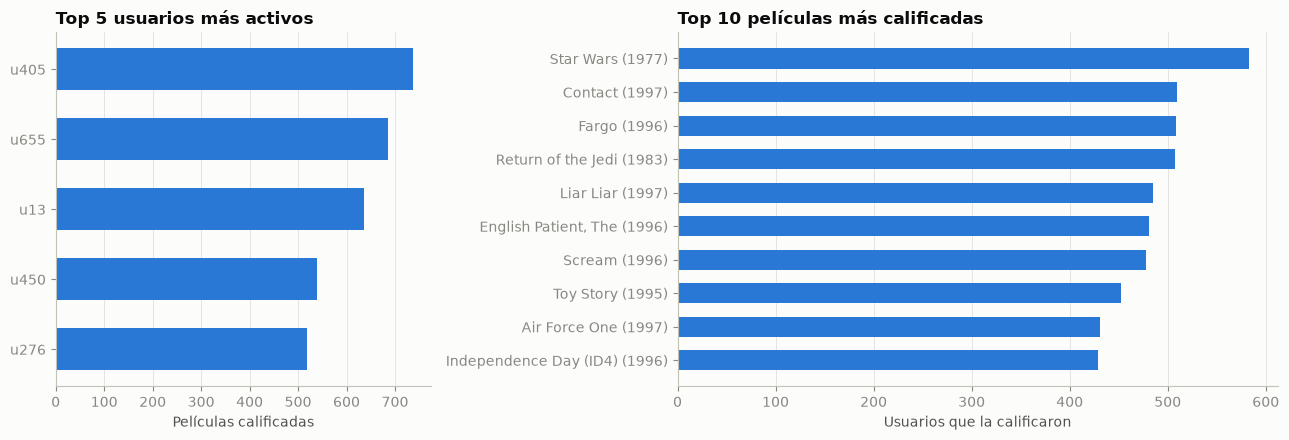

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})

ax1.barh(top_usuarios['nodo'][::-1], top_usuarios['grado'][::-1], color=colores[0], height=0.6)
ax1.set_title(f'Top {n_top_usuarios} usuarios más activos', loc='left')
ax1.set_xlabel('Películas calificadas')
ax1.grid(axis='x'); ax1.set_axisbelow(True)

etiquetas = top_peliculas_grado['titulo'].str.slice(0, 35)[::-1]
ax2.barh(etiquetas, top_peliculas_grado['grado'][::-1], color=colores[0], height=0.6)
ax2.set_title(f'Top {n_top_peliculas} películas más calificadas', loc='left')
ax2.set_xlabel('Usuarios que la calificaron')
ax2.grid(axis='x'); ax2.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### 1.2.2. Películas más centrales: otras medidas

El grado solo cuenta conexiones directas. Para responder qué películas son **más centrales en la red** se agregan dos medidas que miran la estructura completa:

- **PageRank**: una película es importante si la califican usuarios que, a su vez, califican muchas películas importantes.
- **Intermediación (betweenness)**: qué tan seguido una película está en el camino más corto entre otros nodos, es decir, si actúa como "puente" entre grupos de usuarios. El costo del cálculo dependerá de la cantidad de aristas, así que se estima con una muestra de `k_muestra` nodos de origen.

In [10]:
k_muestra = 2625

t0 = time.time()
pagerank = nx.pagerank(G, weight='weight')
intermediacion = nx.betweenness_centrality(G, k=k_muestra, seed=semilla)
print(f'Tiempo de cálculo: {time.time() - t0:.1f} s')

tabla_centralidad = tabla_grado[tabla_grado['tipo'] == 'película'].copy()
tabla_centralidad['titulo'] = tabla_centralidad['nodo'].map(titulo)
tabla_centralidad['pagerank'] = tabla_centralidad['nodo'].map(pagerank)
tabla_centralidad['intermediacion'] = tabla_centralidad['nodo'].map(intermediacion)
for col in ['grado', 'pagerank', 'intermediacion']:
    tabla_centralidad['rank_' + col] = tabla_centralidad[col].rank(ascending=False).astype(int)

top_centrales = tabla_centralidad.nsmallest(n_top_peliculas, 'rank_pagerank')
top_centrales[['nodo', 'titulo', 'grado', 'pagerank', 'intermediacion', 'rank_grado', 'rank_intermediacion']].reset_index(drop=True)

Tiempo de cálculo: 115.1 s


,nodo,titulo,grado,pagerank,intermediacion,rank_grado,rank_intermediacion
0,m50,Star Wars (1977),583,0.003059,0.013299,1,5
1,m258,Contact (1997),509,0.002590,0.014814,2,2
2,m100,Fargo (1996),508,0.002577,0.010243,3,7
3,m181,Return of the Jedi (1983),507,0.002443,0.009921,4,8
4,m286,"English Patient, The (1996)",481,0.002425,0.014773,6,3
5,m288,Scream (1996),478,0.002256,0.015912,7,1
6,m300,Air Force One (1997),431,0.002179,0.010948,9,6
7,m127,"Godfather, The (1972)",413,0.002163,0.007294,12,11
8,m1,Toy Story (1995),452,0.002113,0.007488,8,10
9,m313,Titanic (1997),350,0.002072,0.008668,20,9


#### 1.2.3. Coeficiente de agrupamiento

El coeficiente de agrupamiento clásico cuenta triángulos. En un grafo bipartito **no puede haber triángulos** (dos usuarios nunca están conectados directamente).

Por eso se usa la versión bipartita (Latapy et al.), que mide para cada nodo cuánto se **solapan los vecindarios** de sus vecinos de segundo orden. Para un usuario: qué tanto las películas que él vio coinciden con las de otros usuarios que vieron alguna de sus películas.

In [11]:
modo_agrupamiento = 'dot'   # 'dot' (Jaccard), 'min' o 'max'

t0 = time.time()
agrupamiento = bipartite.clustering(G, mode=modo_agrupamiento)
print(f'Tiempo de cálculo: {time.time() - t0:.1f} s')

tabla_grado['agrupamiento'] = tabla_grado['nodo'].map(agrupamiento)
tabla_grado.groupby('tipo')['agrupamiento'].describe().round(4)

Tiempo de cálculo: 37.1 s


,count,mean,std,min,25%,50%,75%,max
tipo,,,,,,,,
película,1682.0,0.0618,0.0217,0.0080,0.0463,0.0581,0.0768,0.1170
usuario,943.0,0.0888,0.0242,0.0267,0.0710,0.0870,0.1080,0.1437


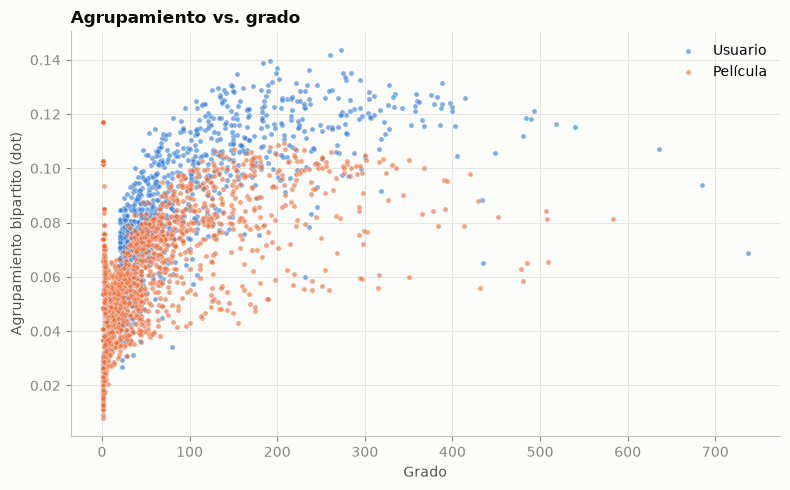

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for tipo, color in [('usuario', colores[0]), ('película', colores[1])]:
    sub = tabla_grado[tabla_grado['tipo'] == tipo]
    ax.scatter(sub['grado'], sub['agrupamiento'], s=14, alpha=0.6, color=color,
               edgecolors='#fcfcfb', linewidths=0.4, label=tipo.capitalize())
#ax.set_xscale('log')
ax.set_xlabel('Grado')
ax.set_ylabel(f'Agrupamiento bipartito ({modo_agrupamiento})')
ax.set_title('Agrupamiento vs. grado', loc='left')
ax.grid(True); ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

#### 1.2.4. Detección de comunidades

**Louvain** sobre el grafo completo. Para ver comunidades en toda la red se usa Louvain, que optimiza la modularidad directamente y escala a grafos grandes. Para cada comunidad se listan sus películas con más calificaciones dentro de la comunidad.

In [13]:
resolucion = 1.0      # >1 produce más comunidades y más pequeñas
n_titulos_comunidad = 5

t0 = time.time()
comunidades_louvain = community.louvain_communities(G, weight='weight', resolution=resolucion, seed=semilla)
comunidades_louvain = sorted(comunidades_louvain, key=len, reverse=True)
print(f'Tiempo de cálculo: {time.time() - t0:.1f} s')
print(f'Comunidades: {len(comunidades_louvain)} | Modularidad: {community.modularity(G, comunidades_louvain, weight="weight"):.4f}')

resumen_louvain = pd.DataFrame([{
    'comunidad': i,
    'usuarios': sum(n.startswith('u') for n in c),
    'películas': sum(n.startswith('m') for n in c),
    'películas representativas': '; '.join(
        titulo[n][:30] for n in sorted((n for n in c if n.startswith('m')),
                                       key=lambda n: G.subgraph(c).degree(n), reverse=True)[:n_titulos_comunidad]),
} for i, c in enumerate(comunidades_louvain)])
resumen_louvain

Tiempo de cálculo: 1.2 s
Comunidades: 4 | Modularidad: 0.2570


,comunidad,usuarios,películas,películas representativas
0,0,200,572,Raiders of the Lost Ark (1981); Empire Strikes...
1,1,231,505,"Silence of the Lambs, The (199; Pulp Fiction (..."
2,2,262,316,Fargo (1996); Jerry Maguire (1996); Toy Story ...
3,3,250,289,"Air Force One (1997); English Patient, The (19..."


#### 1.2.5. Visualización de la red con enfoque en comunidades

Se dibuja el subgrafo de Girvan-Newman. El color indica la comunidad, la forma el tipo de nodo (círculo = usuario, cuadrado = película) y el tamaño el grado dentro del subgrafo. Se etiquetan las películas con más conexiones.

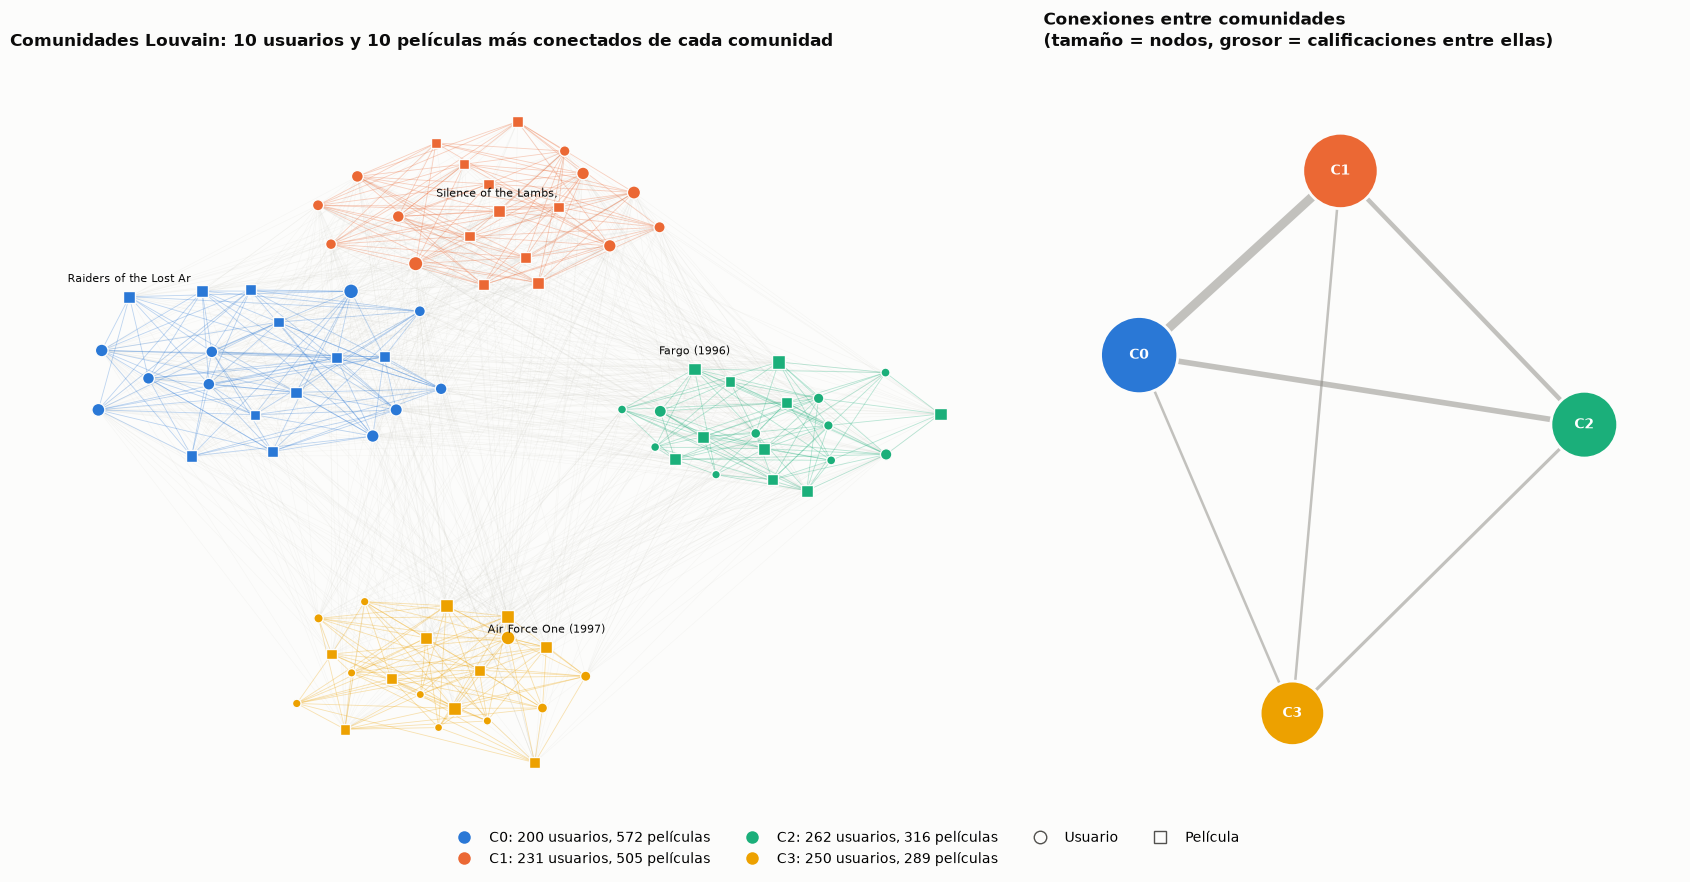

In [14]:
n_comunidades_vis = len(colores)   # se dibujan las comunidades más grandes (máximo 8, una por color)
n_usuarios_por_comunidad = 10
n_peliculas_por_comunidad = 10
radio_comunidad = 0.35
n_caracteres_titulo = 22

comunidades_vis = comunidades_louvain[:n_comunidades_vis]
comunidad_de = {n: i for i, c in enumerate(comunidades_louvain) for n in c}

# --- Grafo de comunidades: un nodo por comunidad, aristas = calificaciones entre comunidades ---
C = nx.Graph()
for i, c in enumerate(comunidades_vis):
    C.add_node(i, tamaño=len(c))
for u, m in G.edges():
    cu, cm = comunidad_de[u], comunidad_de[m]
    if cu != cm and cu < n_comunidades_vis and cm < n_comunidades_vis:
        peso_actual = C.get_edge_data(cu, cm, {'weight': 0})['weight']
        C.add_edge(cu, cm, weight=peso_actual + 1)
centros = nx.spring_layout(C, weight='weight', seed=semilla)

# --- Muestra de nodos: los más conectados dentro de cada comunidad ---
pos, muestra, destacadas = {}, [], []
for i, c in enumerate(comunidades_vis):
    sub = G.subgraph(c)
    usuarios_c = sorted((n for n in c if n.startswith('u')), key=sub.degree, reverse=True)[:n_usuarios_por_comunidad]
    peliculas_c = sorted((n for n in c if n.startswith('m')), key=sub.degree, reverse=True)[:n_peliculas_por_comunidad]
    pos_local = nx.kamada_kawai_layout(G.subgraph(usuarios_c + peliculas_c))
    pos.update({n: centros[i] + radio_comunidad * xy for n, xy in pos_local.items()})
    muestra += usuarios_c + peliculas_c
    if peliculas_c:
        destacadas.append(peliculas_c[0])
M = G.subgraph(muestra)
aristas_internas = [(u, m) for u, m in M.edges() if comunidad_de[u] == comunidad_de[m]]
aristas_externas = [(u, m) for u, m in M.edges() if comunidad_de[u] != comunidad_de[m]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 8.5), gridspec_kw={'width_ratios': [1.6, 1]})

# --- Panel 1: red muestreada ---
nx.draw_networkx_edges(M, pos, edgelist=aristas_externas, edge_color='#c3c2b7', alpha=0.12, width=0.4, ax=ax1)
nx.draw_networkx_edges(M, pos, edgelist=aristas_internas, alpha=0.3, width=0.6, ax=ax1,
                       edge_color=[colores[comunidad_de[u]] for u, _ in aristas_internas])
for tipo, forma in [('usuario', 'o'), ('película', 's')]:
    nodos = [n for n in M.nodes if G.nodes[n]['tipo'] == tipo]
    nx.draw_networkx_nodes(M, pos, nodelist=nodos, node_shape=forma, ax=ax1,
                           node_color=[colores[comunidad_de[n]] for n in nodos],
                           node_size=[25 + 0.12 * G.degree(n) for n in nodos],
                           edgecolors='#fcfcfb', linewidths=1)
nx.draw_networkx_labels(M, {n: (pos[n][0], pos[n][1] + 0.07) for n in destacadas},
                        labels={n: titulo[n][:n_caracteres_titulo] for n in destacadas},
                        font_size=8, font_color='#0b0b0b', ax=ax1)
ax1.set_title(f'Comunidades Louvain: {n_usuarios_por_comunidad} usuarios y {n_peliculas_por_comunidad} películas '
              f'más conectados de cada comunidad', loc='left')
ax1.axis('off')

# --- Panel 2: grafo de comunidades ---
pesos_c = [w for _, _, w in C.edges(data='weight')]
nx.draw_networkx_edges(C, centros, ax=ax2, edge_color='#898781', alpha=0.5,
                       width=[0.5 + 6 * w / max(pesos_c) for w in pesos_c] if pesos_c else 1)
nx.draw_networkx_nodes(C, centros, ax=ax2, node_color=[colores[i] for i in C.nodes],
                       node_size=[C.nodes[i]['tamaño'] * 4 for i in C.nodes], edgecolors='#fcfcfb', linewidths=2)
nx.draw_networkx_labels(C, centros, labels={i: f'C{i}' for i in C.nodes}, font_size=10, font_color='#ffffff',
                        font_weight='bold', ax=ax2)
ax2.set_title('Conexiones entre comunidades\n(tamaño = nodos, grosor = calificaciones entre ellas)', loc='left')
ax2.margins(0.15)
ax2.axis('off')

leyenda = [Line2D([0], [0], marker='o', linestyle='', markersize=9, markerfacecolor=colores[i], markeredgecolor='none',
                  label=f'C{i}: {sum(n.startswith("u") for n in c)} usuarios, {sum(n.startswith("m") for n in c)} películas')
           for i, c in enumerate(comunidades_vis)]
leyenda += [Line2D([0], [0], marker='o', linestyle='', markersize=9, markerfacecolor='none', markeredgecolor='#52514e', label='Usuario'),
            Line2D([0], [0], marker='s', linestyle='', markersize=9, markerfacecolor='none', markeredgecolor='#52514e', label='Película')]
fig.legend(handles=leyenda, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
plt.show()

if len(comunidades_louvain) > n_comunidades_vis:
    print(f'Se muestran {n_comunidades_vis} de {len(comunidades_louvain)} comunidades (las más grandes).')

## 2. Sistema de recomendación con `surprise`

### 2.1. Preparación del conjunto de datos

`Reader('ml-100k')` ya trae el formato de `u.data` (usuario, ítem, rating, timestamp separados por tabulación, escala 1–5). Los IDs quedan como texto.

In [15]:
reader = Reader('ml-100k')
data = Dataset.load_from_file(os.path.join(ruta_carpeta, 'u.data'), reader=reader)

trainset_completo = data.build_full_trainset()
print(f'Calificaciones: {trainset_completo.n_ratings:,} | Usuarios: {trainset_completo.n_users} | Películas: {trainset_completo.n_items}')
pd.DataFrame(data.raw_ratings[:5], columns=['user', 'item', 'rating', 'timestamp'])

Calificaciones: 100,000 | Usuarios: 943 | Películas: 1682


,user,item,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


### 2.2. Entrenamiento de los modelos

Se separa un 25 % de las calificaciones como conjunto de prueba.

Modelos:
1. **SVD**: filtrado colaborativo por factorización de matrices.
2. **KNN usuario**: predice con las calificaciones de los usuarios más parecidos.

In [16]:
test_size = 0.25
k_vecinos = 40
similitud = 'msd'   # 'msd', 'cosine', 'pearson' o 'pearson_baseline'

trainset, testset = train_test_split(data, test_size=test_size, random_state=semilla)

modelos = {
    'SVD': SVD(random_state=semilla),
    'KNN usuario-usuario': KNNBasic(k=k_vecinos, sim_options={'name': similitud, 'user_based': True}, verbose=False)
}

resultados = []
for nombre, algo in modelos.items():
    t0 = time.time()
    algo.fit(trainset)
    predicciones = algo.test(testset)
    resultados.append({'modelo': nombre, 'etapa': 'base',
                       'RMSE': accuracy.rmse(predicciones, verbose=False),
                       'MAE': accuracy.mae(predicciones, verbose=False),
                       'tiempo_s': round(time.time() - t0, 1)})

tabla_base = pd.DataFrame(resultados)
tabla_base

,modelo,etapa,RMSE,MAE,tiempo_s
0,SVD,base,0.939557,0.740769,0.9
1,KNN usuario-usuario,base,0.985369,0.777509,2.2


In [17]:
user_id = '196'
movie_id = '302'

real = ratings[(ratings['user'] == int(user_id)) & (ratings['item'] == int(movie_id))]['rating']
r_real = real.iloc[0] if len(real) else None

prediccion = modelos['SVD'].predict(user_id, movie_id, r_ui=r_real, verbose=True)
print(f"Película: {titulo.get('m' + movie_id, '?')}")
print(f'Predicción SVD: {prediccion.est:.2f} | Rating real: {r_real}')

user: 196        item: 302        r_ui = None   est = 4.19   {'was_impossible': False}
Película: L.A. Confidential (1997)
Predicción SVD: 4.19 | Rating real: None


### 2.3. Ajuste de hiperparámetros con grid search

`GridSearchCV` hace validación cruzada para cada combinación de la grilla. Para no "contaminar" la evaluación, el grid search se corre **solo con el conjunto de entrenamiento**.

Hiperparámetros:
- **SVD**: `n_factors` (factores latentes), `n_epochs` (iteraciones), `lr_all` (tasa de aprendizaje), `reg_all` (regularización).
- **KNN**: `k` (vecinos), medida de similitud y si es usuario-usuario o ítem-ítem.

Con `n_jobs=-1` se usan todos los núcleos del procesador. (Si da problemas al ejecutar, se puede establecer como `1`).

In [18]:
cv_folds = 5
n_jobs = -1

df_train = pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                        columns=['user', 'item', 'rating'])
data_train = Dataset.load_from_df(df_train, Reader(rating_scale=(1, 5)))
print(f'Calificaciones para el grid search: {len(df_train):,}')

Calificaciones para el grid search: 75,000


In [19]:
param_grid_svd = {
    'n_factors': [50, 100, 150],
    'n_epochs': [20, 40],
    'lr_all': [0.005, 0.01],
    'reg_all': [0.02, 0.1],
    'random_state': [semilla],
}

t0 = time.time()
gs_svd = GridSearchCV(SVD, param_grid_svd, measures=['rmse', 'mae'], cv=cv_folds, n_jobs=n_jobs)
gs_svd.fit(data_train)
print(f'Tiempo: {time.time() - t0:.0f} s')
print('Mejor RMSE (validación cruzada):', round(gs_svd.best_score['rmse'], 4))
print('Mejores parámetros:', gs_svd.best_params['rmse'])

cv_svd = pd.DataFrame(gs_svd.cv_results)
cv_svd[['param_n_factors', 'param_n_epochs', 'param_lr_all', 'param_reg_all', 'mean_test_rmse', 'mean_test_mae']] \
    .sort_values('mean_test_rmse').head(10).reset_index(drop=True)

Tiempo: 18 s
Mejor RMSE (validación cruzada): 0.9237
Mejores parámetros: {'n_factors': 150, 'n_epochs': 40, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}


,param_n_factors,param_n_epochs,param_lr_all,param_reg_all,mean_test_rmse,mean_test_mae
0,150,40,0.010,0.1,0.923737,0.731669
1,100,40,0.010,0.1,0.924834,0.732070
2,50,40,0.010,0.1,0.925558,0.731839
3,150,40,0.005,0.1,0.930904,0.738046
4,150,20,0.010,0.1,0.931296,0.738398
5,100,40,0.005,0.1,0.932153,0.738669
6,100,20,0.010,0.1,0.932629,0.739060
7,50,40,0.005,0.1,0.933846,0.739820
8,50,20,0.010,0.1,0.934471,0.740360
9,150,20,0.005,0.1,0.944623,0.749853


In [20]:
clase_knn = KNNBasic

param_grid_knn = {
    'k': [10, 20, 40, 60, 80],
    'sim_options': {'name': ['msd', 'pearson_baseline'], 'user_based': [True]},
    'verbose': [False],
}

t0 = time.time()
gs_knn = GridSearchCV(clase_knn, param_grid_knn, measures=['rmse', 'mae'], cv=cv_folds, n_jobs=n_jobs)
gs_knn.fit(data_train)
print(f'Tiempo: {time.time() - t0:.0f} s')
print('Mejor RMSE (validación cruzada):', round(gs_knn.best_score['rmse'], 4))
print('Mejores parámetros:', gs_knn.best_params['rmse'])

cv_knn = pd.DataFrame(gs_knn.cv_results)
cv_knn['similitud'] = cv_knn['param_sim_options'].apply(lambda s: s['name'])
cv_knn['enfoque'] = cv_knn['param_sim_options'].apply(lambda s: 'usuario-usuario' if s['user_based'] else 'ítem-ítem')
cv_knn[['param_k', 'similitud', 'enfoque', 'mean_test_rmse', 'mean_test_mae']] \
    .sort_values('mean_test_rmse').head(10).reset_index(drop=True)

Tiempo: 13 s
Mejor RMSE (validación cruzada): 0.9948
Mejores parámetros: {'k': 20, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}


,param_k,similitud,enfoque,mean_test_rmse,mean_test_mae
0,20,msd,usuario-usuario,0.994780,0.785453
1,40,msd,usuario-usuario,0.994818,0.786681
2,60,msd,usuario-usuario,0.999084,0.791020
3,80,msd,usuario-usuario,1.002594,0.794598
4,10,msd,usuario-usuario,1.007677,0.795155
5,40,pearson_baseline,usuario-usuario,1.016980,0.803334
6,60,pearson_baseline,usuario-usuario,1.017119,0.803567
7,80,pearson_baseline,usuario-usuario,1.017247,0.803703
8,20,pearson_baseline,usuario-usuario,1.019634,0.805384
9,10,pearson_baseline,usuario-usuario,1.032001,0.815596


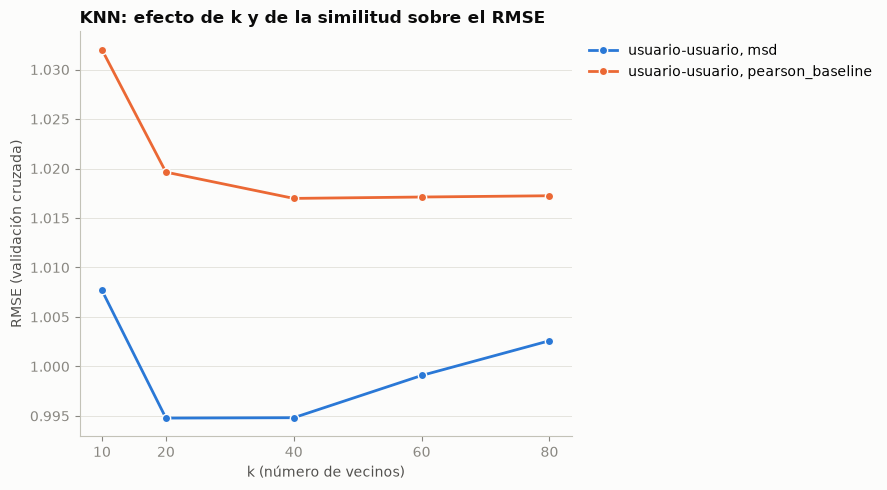

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
for i, ((sim, enfoque), sub) in enumerate(cv_knn.groupby(['similitud', 'enfoque'])):
    sub = sub.sort_values('param_k')
    ax.plot(sub['param_k'], sub['mean_test_rmse'], color=colores[i], linewidth=2,
            marker='o', markersize=6, markeredgecolor='#fcfcfb', label=f'{enfoque}, {sim}')
ax.set_xlabel('k (número de vecinos)')
ax.set_ylabel('RMSE (validación cruzada)')
ax.set_title('KNN: efecto de k y de la similitud sobre el RMSE', loc='left')
ax.set_xticks(sorted(cv_knn['param_k'].unique()))
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

### 2.4. Evaluación final sobre el conjunto de prueba

In [22]:
modelos_ajustados = {
    'SVD': SVD(**gs_svd.best_params['rmse']),
    'KNN (mejor configuración)': clase_knn(**gs_knn.best_params['rmse']),
}

for nombre, algo in modelos_ajustados.items():
    t0 = time.time()
    algo.fit(trainset)
    predicciones = algo.test(testset)
    resultados.append({'modelo': nombre, 'etapa': 'ajustado',
                       'RMSE': accuracy.rmse(predicciones, verbose=False),
                       'MAE': accuracy.mae(predicciones, verbose=False),
                       'tiempo_s': round(time.time() - t0, 1)})

tabla_final = pd.DataFrame(resultados).sort_values('RMSE').reset_index(drop=True)
tabla_final['configuración'] = ''
tabla_final.loc[tabla_final['etapa'].eq('ajustado') & tabla_final['modelo'].eq('SVD'), 'configuración'] = str(gs_svd.best_params['rmse'])
tabla_final.loc[tabla_final['etapa'].eq('ajustado') & tabla_final['modelo'].str.startswith('KNN'), 'configuración'] = str(gs_knn.best_params['rmse'])
tabla_final.round(4)
# En la interpretación, el menor valor es el mejor

,modelo,etapa,RMSE,MAE,tiempo_s,configuración
0,SVD,ajustado,0.9161,0.7229,1.5,"{'n_factors': 150, 'n_epochs': 40, 'lr_all': 0..."
1,SVD,base,0.9396,0.7408,0.9,
2,KNN (mejor configuración),ajustado,0.9831,0.7746,1.6,"{'k': 20, 'sim_options': {'name': 'msd', 'user..."
3,KNN usuario-usuario,base,0.9854,0.7775,2.2,


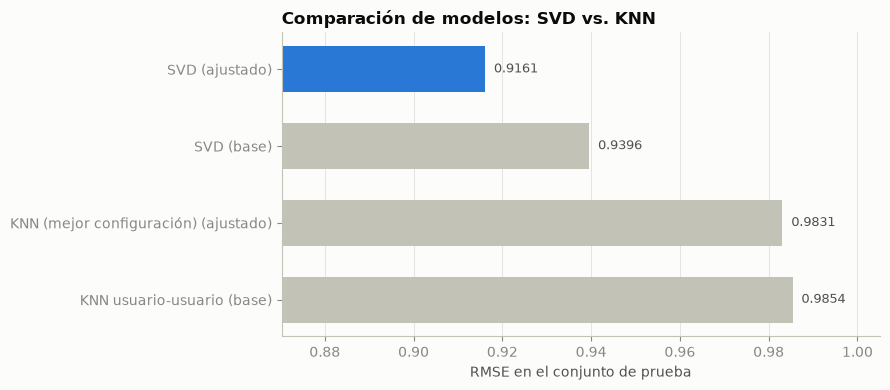

In [23]:
etiquetas = tabla_final['modelo'] + ' (' + tabla_final['etapa'] + ')'
mejor = tabla_final['RMSE'].idxmin()

fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(etiquetas[::-1], tabla_final['RMSE'][::-1], height=0.6,
                 color=[colores[0] if i == mejor else color_otros for i in tabla_final.index[::-1]])
for barra, valor in zip(barras, tabla_final['RMSE'][::-1]):
    ax.text(barra.get_width() + 0.002, barra.get_y() + barra.get_height() / 2, f'{valor:.4f}',
            va='center', fontsize=9, color='#52514e')
ax.set_xlim(tabla_final['RMSE'].min() * 0.95, tabla_final['RMSE'].max() * 1.02)
ax.set_xlabel('RMSE en el conjunto de prueba')
ax.set_title('Comparación de modelos: SVD vs. KNN', loc='left')
ax.grid(axis='x'); ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Conclusiones**
- El modelo SVD ajustado en sus hiperparámetros es el modelo que tiene menor error.
- La modificación de parámetros hizo una diferencia para el modelo con SVD, pero no para KNN.

### 2.5. Top-5 de recomendaciones para un usuario

Para recomendar se usa el modelo con menor RMSE, reentrenado con **todas** las calificaciones (el split solo servía para evaluar). Se predicen las películas que el usuario aún no ha calificado y se ordenan por calificación estimada.

Primero se muestra lo que el usuario mejor calificó, para contrastar sus gustos con las recomendaciones.

In [32]:
user_id = '900'
n_recomendaciones = 5

mejor_modelo = tabla_final[tabla_final['etapa'] == 'ajustado'].iloc[0]['modelo']
if mejor_modelo == 'SVD':
    modelo_final = SVD(**gs_svd.best_params['rmse'])
else:
    modelo_final = clase_knn(**gs_knn.best_params['rmse'])
modelo_final.fit(trainset_completo)
print(f'Modelo usado: {mejor_modelo}')

# Lo que el usuario mejor calificó
top_real = (ratings[ratings['user'] == int(user_id)]
            .sort_values(['rating', 'timestamp'], ascending=[False, False])
            .head(n_recomendaciones)
            .merge(peliculas, on='item', how='left'))
print(f'\nPelículas mejor calificadas por el usuario {user_id} '
      f'(calificó {len(ratings[ratings["user"] == int(user_id)])} en total):')
display(top_real[['item', 'titulo', 'rating']])

# Recomendaciones: películas no vistas ordenadas por rating estimado
uid_interno = trainset_completo.to_inner_uid(user_id)
vistas = {iid for (iid, _) in trainset_completo.ur[uid_interno]}
no_vistas = [trainset_completo.to_raw_iid(iid) for iid in trainset_completo.all_items() if iid not in vistas]

predicciones_usuario = sorted((modelo_final.predict(user_id, iid) for iid in no_vistas),
                              key=lambda p: p.est, reverse=True)

top_recomendado = pd.DataFrame([(int(p.iid), p.est) for p in predicciones_usuario[:n_recomendaciones]],
                               columns=['item', 'rating_estimado']).merge(peliculas, on='item', how='left')
print(f'Top {n_recomendaciones} recomendaciones para el usuario {user_id}:')
top_recomendado[['item', 'titulo', 'rating_estimado']].round(3)

Modelo usado: SVD

Películas mejor calificadas por el usuario 900 (calificó 45 en total):


,item,titulo,rating
0,589,"Wild Bunch, The (1969)",5
1,618,Picnic (1955),4
2,483,Casablanca (1942),4
3,474,Dr. Strangelove or: How I Learned to Stop Worr...,4
4,661,High Noon (1952),4


Top 5 recomendaciones para el usuario 900:


,item,titulo,rating_estimado
0,1449,Pather Panchali (1955),3.737
1,169,"Wrong Trousers, The (1993)",3.640
2,408,"Close Shave, A (1995)",3.582
3,12,"Usual Suspects, The (1995)",3.552
4,114,Wallace & Gromit: The Best of Aardman Animatio...,3.523


**¿Es fiel la recomendación con respecto a la comunidad del usuario?**

In [33]:
nodo_usuario = 'u' + user_id
comunidad_de = {n: i for i, c in enumerate(comunidades_louvain) for n in c}
comunidad_usuario = comunidad_de[nodo_usuario]

print(f'El usuario {user_id} pertenece a la comunidad C{comunidad_usuario}')
display(resumen_louvain[resumen_louvain['comunidad'] == comunidad_usuario])

# ¿Las películas recomendadas están en la comunidad del usuario?
top_recomendado['comunidad'] = ('m' + top_recomendado['item'].astype(str)).map(comunidad_de)
top_recomendado['misma_comunidad'] = top_recomendado['comunidad'] == comunidad_usuario
print(f'\nRecomendaciones dentro de su comunidad: {top_recomendado["misma_comunidad"].sum()} de {len(top_recomendado)}')
top_recomendado[['item', 'titulo', 'rating_estimado', 'comunidad', 'misma_comunidad']].round(3)

El usuario 900 pertenece a la comunidad C2


,comunidad,usuarios,películas,películas representativas
2,2,262,316,Fargo (1996); Jerry Maguire (1996); Toy Story ...



Recomendaciones dentro de su comunidad: 1 de 5


,item,titulo,rating_estimado,comunidad,misma_comunidad
0,1449,Pather Panchali (1955),3.737,1,False
1,169,"Wrong Trousers, The (1993)",3.640,1,False
2,408,"Close Shave, A (1995)",3.582,2,True
3,12,"Usual Suspects, The (1995)",3.552,1,False
4,114,Wallace & Gromit: The Best of Aardman Animatio...,3.523,1,False
